In [ ]:
house-prices-advanced-regression-techniques

In [113]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder,LabelEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import  root_mean_squared_error, mean_absolute_error, r2_score

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
sns.set()

In [12]:
train=pd.read_csv('/Users/pujadas/Downloads/house-prices-advanced-regression-techniques/train.csv', index_col='Id')

In [13]:
test=pd.read_csv('/Users/pujadas/Downloads/house-prices-advanced-regression-techniques/train.csv', index_col='Id')

In [14]:
train.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [91]:
X_train=train.iloc[:,:-1]
Y_train=train.iloc[:,-1]
X_test=test.iloc[:,:-1]
Y_test=test.iloc[:,-1]

In [92]:
nume_col = train.iloc[:,:-1].select_dtypes(include=['number']).columns.tolist()
cate_col = train.iloc[:,:-1].select_dtypes(exclude=['number']).columns.tolist()

In [94]:
nume_col

['MSSubClass',
 'LotFrontage',
 'LotArea',
 'OverallQual',
 'OverallCond',
 'YearBuilt',
 'YearRemodAdd',
 'MasVnrArea',
 'BsmtFinSF1',
 'BsmtFinSF2',
 'BsmtUnfSF',
 'TotalBsmtSF',
 '1stFlrSF',
 '2ndFlrSF',
 'LowQualFinSF',
 'GrLivArea',
 'BsmtFullBath',
 'BsmtHalfBath',
 'FullBath',
 'HalfBath',
 'BedroomAbvGr',
 'KitchenAbvGr',
 'TotRmsAbvGrd',
 'Fireplaces',
 'GarageYrBlt',
 'GarageCars',
 'GarageArea',
 'WoodDeckSF',
 'OpenPorchSF',
 'EnclosedPorch',
 '3SsnPorch',
 'ScreenPorch',
 'PoolArea',
 'MiscVal',
 'MoSold',
 'YrSold']

In [95]:
cate_col

['MSZoning',
 'Street',
 'Alley',
 'LotShape',
 'LandContour',
 'Utilities',
 'LotConfig',
 'LandSlope',
 'Neighborhood',
 'Condition1',
 'Condition2',
 'BldgType',
 'HouseStyle',
 'RoofStyle',
 'RoofMatl',
 'Exterior1st',
 'Exterior2nd',
 'MasVnrType',
 'ExterQual',
 'ExterCond',
 'Foundation',
 'BsmtQual',
 'BsmtCond',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtFinType2',
 'Heating',
 'HeatingQC',
 'CentralAir',
 'Electrical',
 'KitchenQual',
 'Functional',
 'FireplaceQu',
 'GarageType',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'PavedDrive',
 'PoolQC',
 'Fence',
 'MiscFeature',
 'SaleType',
 'SaleCondition']

In [96]:
X_train.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal


In [97]:
X_train_nume=X_train[nume_col].columns.tolist()
X_train_cate=X_train[cate_col].columns.tolist()
X_test_nume=X_test[nume_col].columns.tolist()
X_test_cate=X_test[cate_col].columns.tolist()


In [98]:
preprocessor=ColumnTransformer(
    transformers=[
        (
            'num',Pipeline(steps=[
                ('imputer',SimpleImputer(strategy='mean')),
                ('scaler',StandardScaler())
            ]
                
            ),X_train_nume
        ),
        (
            'cate',Pipeline(steps=[
                ('imputer',SimpleImputer(strategy='most_frequent')),
                ('encoder',OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
            ]
                
            ),X_train_cate
        )
    ]
)
    

In [101]:
params_grid = {
    'reg__n_estimators': [50, 100, 200],       
    'reg__max_depth': [None, 10, 20],             
    'reg__min_samples_split': [2, 10, 50],
    'reg__max_features': ['sqrt', 'log2', 0.3, 0.5]
}
pipeline=Pipeline(
    steps=[
        ('preprocessor',preprocessor),
        ('reg', RandomForestRegressor())
    ]
)
gridSearch=GridSearchCV(
    pipeline,
    params_grid,
    cv=5,
    n_jobs=1,
    scoring='neg_mean_squared_error',
    error_score='raise'
)

In [102]:
gridSearch.fit(X_train,Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'reg__max_depth': [None, 10, ...], 'reg__max_features': ['sqrt', 'log2', ...], 'reg__min_samples_split': [2, 10, ...], 'reg__n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >

In [103]:
gridSearch.best_params_

{'reg__max_depth': None,
 'reg__max_features': 0.3,
 'reg__min_samples_split': 2,
 'reg__n_estimators': 100}

In [104]:
gridSearch.best_score_

-825505305.9702253

In [105]:
gridSearch.best_estimator_

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('reg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cate', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers con

In [106]:
final_model=gridSearch.best_estimator_

In [107]:
feature_names=final_model.named_steps['preprocessor'].get_feature_names_out

In [108]:
feature_importance=final_model.named_steps['reg'].feature_importances_

In [109]:
result_df=pd.DataFrame({"feature_name":feature_names, "feature_importance": feature_importance})
result_df.sort_values(by="feature_importance", ascending= False)
                                                                                                         

,feature_name,feature_importance
3,<bound method ColumnTransformer.get_feature_na...,0.216314
25,<bound method ColumnTransformer.get_feature_na...,0.124838
15,<bound method ColumnTransformer.get_feature_na...,0.109426
54,<bound method ColumnTransformer.get_feature_na...,0.072601
11,<bound method ColumnTransformer.get_feature_na...,0.054013
...,...,...
33,<bound method ColumnTransformer.get_feature_na...,0.000113
72,<bound method ColumnTransformer.get_feature_na...,0.000068
37,<bound method ColumnTransformer.get_feature_na...,0.000025
76,<bound method ColumnTransformer.get_feature_na...,0.000024


In [150]:
y_pred=gridSearch.predict(X_test)

In [151]:
y_pred[:10]

array([208020.  , 176510.6 , 221648.  , 150610.38, 268715.59, 141961.32,
       297233.92, 207777.7 , 137428.  , 118729.88])

In [152]:
rmse=root_mean_squared_error(Y_test,y_pred) 
mae= mean_absolute_error(Y_test,y_pred)
r2= r2_score(Y_test,y_pred)

In [153]:
print(rmse,mae,r2)

10427.530031768865 6096.807897260275 0.9827593106868955


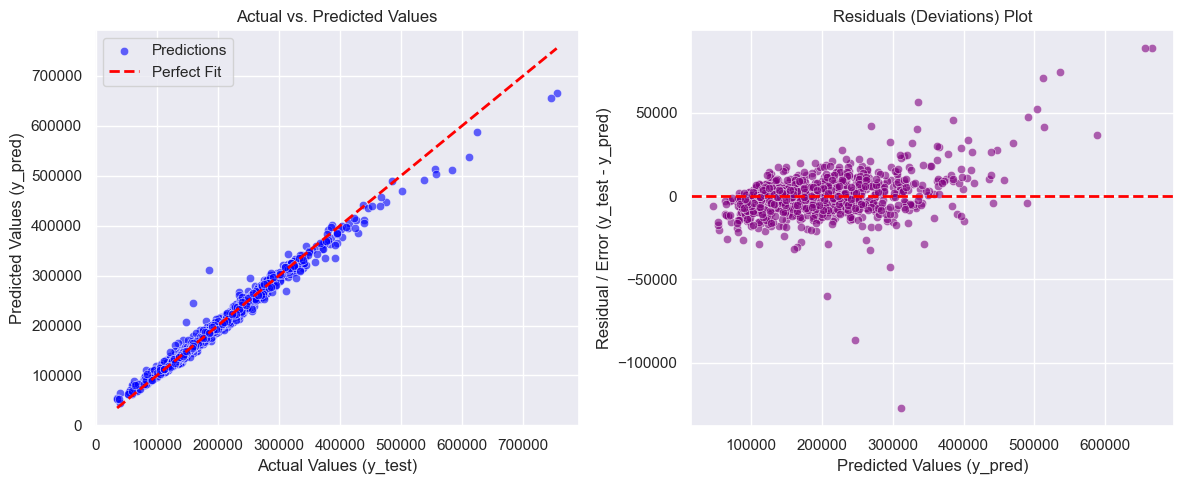

In [154]:

plt.figure(figsize=(12, 5))

# Subplot 1: Actual vs Predicted
plt.subplot(1, 2, 1)
sns.scatterplot(x=Y_test, y=y_pred, alpha=0.6, color='blue', label='Predictions')
# Draw a perfect 1:1 line where y_test == y_pred
perfect_line = [min(Y_test), max(Y_test)]
plt.plot(perfect_line, perfect_line, color='red', linestyle='--', linewidth=2, label='Perfect Fit')
plt.title('Actual vs. Predicted Values')
plt.xlabel('Actual Values (y_test)')
plt.ylabel('Predicted Values (y_pred)')
plt.legend()
plt.grid(True)

# Subplot 2: Residuals Plot (The Deviation/Error)
plt.subplot(1, 2, 2)
residuals = Y_test - y_pred  # Calculate deviation
sns.scatterplot(x=y_pred, y=residuals, alpha=0.6, color='purple')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)  # Zero error line
plt.title('Residuals (Deviations) Plot')
plt.xlabel('Predicted Values (y_pred)')
plt.ylabel('Residual / Error (y_test - y_pred)')
plt.grid(True)

plt.tight_layout()
plt.show()


In [121]:
Y_test

Id
1       208500
2       181500
3       223500
4       140000
5       250000
         ...  
1456    175000
1457    210000
1458    266500
1459    142125
1460    147500
Name: SalePrice, Length: 1460, dtype: int64

In [155]:
y_pred

array([208020.  , 176510.6 , 221648.  , ..., 260219.45, 138548.85,
       149806.77])

In [147]:
pd.set_option('display.float_format', lambda x: '%.10f' % x)

In [165]:
final=pd.DataFrame({"Id": Y_test.index, "SalePrice": y_pred})

In [169]:
final.tail()

,SalePrice
Id,
1456,175251.9000000000
1457,207870.6000000000
1458,260219.4500000000
1459,138548.8500000000
1460,149806.7700000000


In [167]:
final=final.set_index("Id")

In [171]:
Y_test.tail()

Id
1456    175000
1457    210000
1458    266500
1459    142125
1460    147500
Name: SalePrice, dtype: int64

In [168]:
final.to_csv("/Users/pujadas/Downloads/house-prices-advanced-regression-techniques/Kaggle_Sep21_2026_Submission.csv", float_format="%.2f")

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('house-prices-advanced-regression-techniques')

print("Path to competition files:", path)